# Aulas IA Preditiva Modulo1 Semana 07 Aula2

## Graficos em Python Matplotlib

In [2]:
import pandas as pd

# O CSV deve estar na mesma pasta do notebook.
df = pd.read_csv("vendas-didaticas.csv")

# Calcular métricas (recalculadas para deixar o exemplo independente)
df["receita_bruta"] = df["quantidade"] * df["preco_unitario"]
df["receita_liquida"] = df["receita_bruta"] * (1 - df["desconto_pct"] / 100)
df["custo_total"] = df["quantidade"] * df["custo_unitario"]
df["lucro"] = df["receita_liquida"] - df["custo_total"] 

print(df.dtypes)

df.head(10)

id_venda               int64
data                     str
regiao                   str
categoria                str
produto                  str
canal                    str
quantidade             int64
preco_unitario       float64
desconto_pct           int64
custo_unitario       float64
avaliacao_cliente      int64
receita_bruta        float64
receita_liquida      float64
custo_total          float64
lucro                float64
mes                      str
mes_nome                 str
dtype: object


,id_venda,data,regiao,categoria,produto,canal,quantidade,preco_unitario,desconto_pct,custo_unitario,avaliacao_cliente,receita_bruta,receita_liquida,custo_total,lucro,mes,mes_nome
0,1,2024-01-01,Sul,Alimentos,Arroz 5kg,Online,17,23.16,10,13.90,1,393.72,354.348,236.30,118.048,2024-01,Jan/2024
1,2,2024-01-01,Norte,Alimentos,Azeite 500ml,Online,14,31.40,5,18.84,4,439.60,417.620,263.76,153.860,2024-01,Jan/2024
2,3,2024-01-02,Leste,Esportes,Raquete de Tênis,Loja Física,5,350.54,15,180.28,4,1752.70,1489.795,901.40,588.395,2024-01,Jan/2024
3,4,2024-01-02,Leste,Roupas,Tênis,Marketplace,3,304.80,5,152.40,4,914.40,868.680,457.20,411.480,2024-01,Jan/2024
4,5,2024-01-02,Centro,Alimentos,Arroz 5kg,Online,14,27.01,10,16.20,4,378.14,340.326,226.80,113.526,2024-01,Jan/2024
5,6,2024-01-03,Leste,Alimentos,Café 500g,Loja Física,5,15.78,0,8.42,4,78.90,78.900,42.10,36.800,2024-01,Jan/2024
6,7,2024-01-03,Leste,Eletrônicos,Smartwatch,Telefone,8,859.50,20,429.75,2,6876.00,5500.800,3438.00,2062.800,2024-01,Jan/2024
7,8,2024-01-03,Oeste,Roupas,Calça,Online,12,127.33,0,53.05,4,1527.96,1527.960,636.60,891.360,2024-01,Jan/2024
8,9,2024-01-04,Sul,Roupas,Calça,Telefone,10,126.42,5,52.67,1,1264.20,1200.990,526.70,674.290,2024-01,Jan/2024
9,10,2024-01-04,Centro,Móveis,Estante,Loja Física,9,559.87,10,279.94,3,5038.83,4534.947,2519.46,2015.487,2024-01,Jan/2024


In [3]:
# Extrair mês como período
df["mes"] = pd.to_datetime(df["data"]).dt.to_period("M")

# Nome do mês para rótulos
df["mes_nome"] = pd.to_datetime(df["data"]).dt.strftime("%b/%Y")

# Conferir as primeiras linhas
print(df[["data", "mes", "mes_nome"]].head()) 

print(df.dtypes)


         data      mes  mes_nome
0  2024-01-01  2024-01  Jan/2024
1  2024-01-01  2024-01  Jan/2024
2  2024-01-02  2024-01  Jan/2024
3  2024-01-02  2024-01  Jan/2024
4  2024-01-02  2024-01  Jan/2024
id_venda                 int64
data                       str
regiao                     str
categoria                  str
produto                    str
canal                      str
quantidade               int64
preco_unitario         float64
desconto_pct             int64
custo_unitario         float64
avaliacao_cliente        int64
receita_bruta          float64
receita_liquida        float64
custo_total            float64
lucro                  float64
mes                  period[M]
mes_nome                   str
dtype: object


In [4]:
# Recalcular a receita líquida para este exemplo funcionar isoladamente
df["receita_liquida"] = (
    df["quantidade"] * df["preco_unitario"] * (1 - df["desconto_pct"] / 100)
)

# Agrupar por categoria e somar receita líquida
receita_por_categoria = (
    df.groupby("categoria", as_index=False)["receita_liquida"]
        .sum()
        .sort_values("receita_liquida", ascending=False)
)
print(receita_por_categoria) 


     categoria  receita_liquida
1  Eletrônicos      811929.2320
3       Móveis      786421.1180
2     Esportes      547679.7500
4       Roupas      256730.2915
0    Alimentos       33970.1730


In [5]:
# Receita líquida por região e canal
receita_regiao_canal = df.groupby(["regiao", "canal"])["receita_liquida"].sum()
# Transformar canais em colunas
tabela = receita_regiao_canal.unstack(fill_value=0)

print(tabela) 


canal   Loja Física  Marketplace       Online     Telefone
regiao                                                    
Centro  123639.4585  126866.9380   92417.5500  179477.3375
Leste   113740.4925  100797.0865  106159.0190  142291.5890
Norte    98863.2135   88129.3215  150000.8555  123260.3690
Oeste   126754.7270  150937.2980  136478.4045  116256.5255
Sul     108069.4795  121037.1495  127392.5455  104161.2045


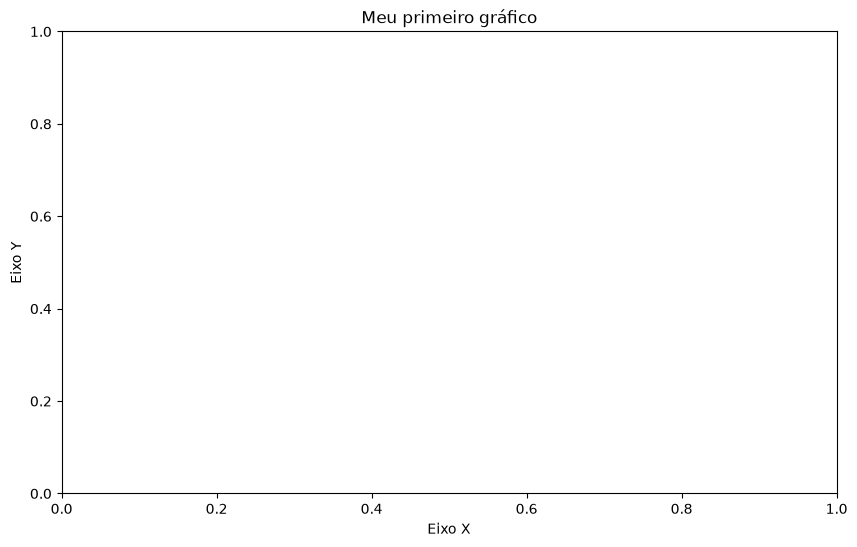

In [ ]:
#%pip install matplotlib

import matplotlib.pyplot as plt

# Cria uma figura e um eixo para receber o gráfico.
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title("Meu primeiro gráfico")
ax.set_xlabel("Eixo X")
ax.set_ylabel("Eixo Y")
plt.show() 


### grafico de linhas Matplotlib

eixo X: Index(['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06',
       '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12'],
      dtype='str', name='data')
eixo Y: [1862.78023214 2189.58141477 2785.74021649 2555.61905714 2814.9690473
 2737.48041304 2112.59855729 2247.6726978  2892.78606452 2699.93894149
 2403.90505422 2187.51167935]


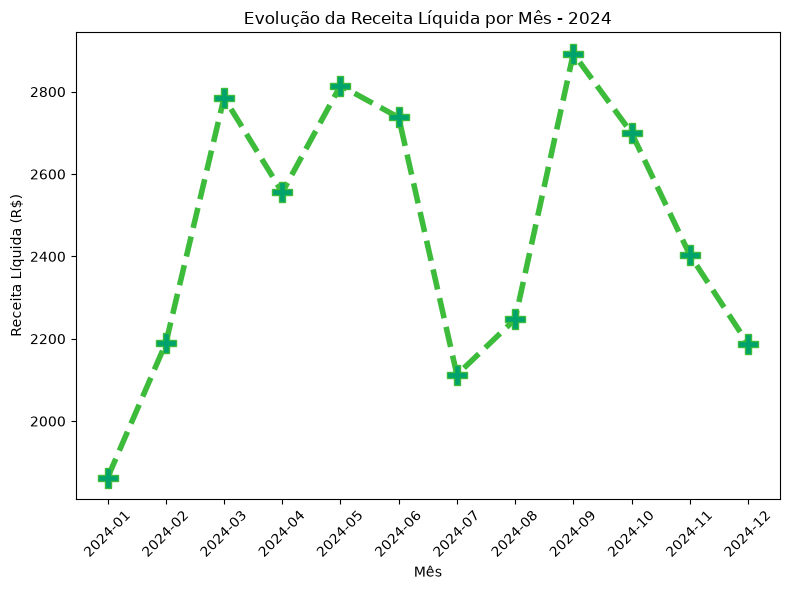

In [ ]:
# grafico de linhas

# Recalcular a receita líquida para este exemplo funcionar isoladamente
df["receita_liquida"] = (
    df["quantidade"] * df["preco_unitario"] * (1 - df["desconto_pct"] / 100)
)
df["data"] = pd.to_datetime(df["data"])
receita_mensal = (
    df.groupby(df["data"].dt.to_period("M"))["receita_liquida"]
        .mean()
        .sort_index()
)

print("eixo X:", receita_mensal.index.astype(str))
print("eixo Y:", receita_mensal.values)

fig, ax = plt.subplots(figsize=(8, 6))
# grafico de linhas
ax.plot(receita_mensal.index.astype(str), receita_mensal.values,
        marker="P", linewidth=4, color="#3DBB3B", markersize=15, markerfacecolor='#00A36C', linestyle='--')
ax.set_xlabel("Mês")
ax.set_ylabel("Receita Líquida (R$)")
ax.set_title("Evolução da Receita Líquida por Mês - 2024")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show() 


### grafico de linhas Seaborn

In [ ]:
#%pip install seaborn
import seaborn as sns

# Configuração visual global para os gráficos deste notebook
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14 


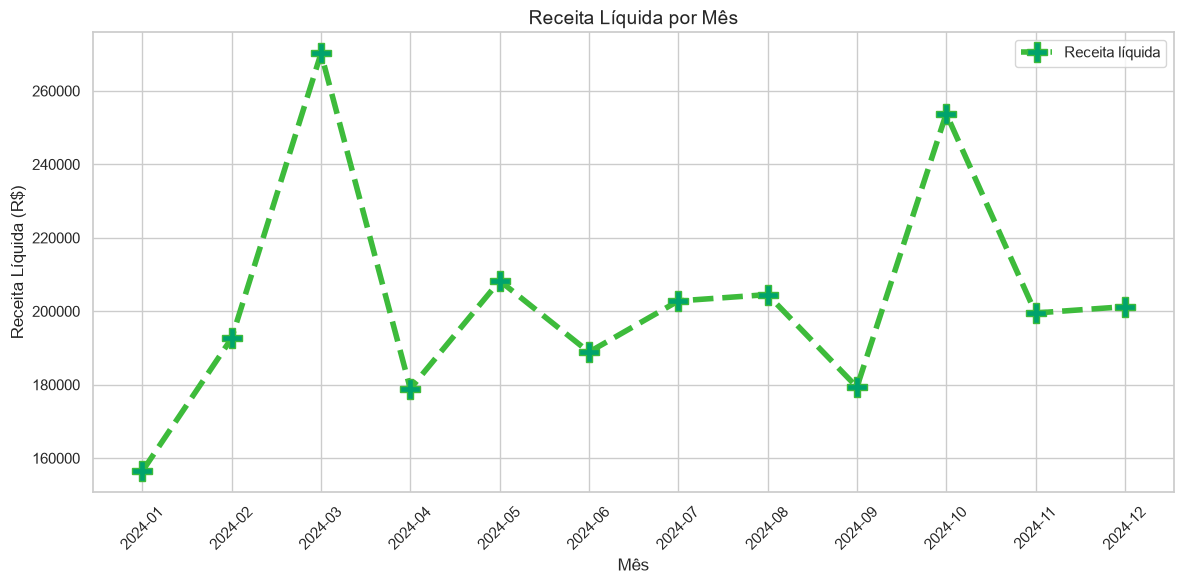

In [33]:
# Recalcular a receita líquida para este exemplo funcionar isoladamente
df["receita_liquida"] = (
    df["quantidade"] * df["preco_unitario"] * (1 - df["desconto_pct"] / 100)
)
df["mes"] = pd.to_datetime(df["data"]).dt.to_period("M")
por_mes = (
    df.groupby("mes", as_index=False)["receita_liquida"]
        .sum()
        .sort_values("mes")
)
fig, ax = plt.subplots()
ax.plot(por_mes["mes"].astype(str), por_mes["receita_liquida"],
    marker="P", linewidth=4, color="#3DBB3B", markersize=15, markerfacecolor='#00A36C', linestyle='--', label="Receita líquida")
ax.set_title("Receita Líquida por Mês")
ax.set_xlabel("Mês")
ax.set_ylabel("Receita Líquida (R$)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
plt.show() 


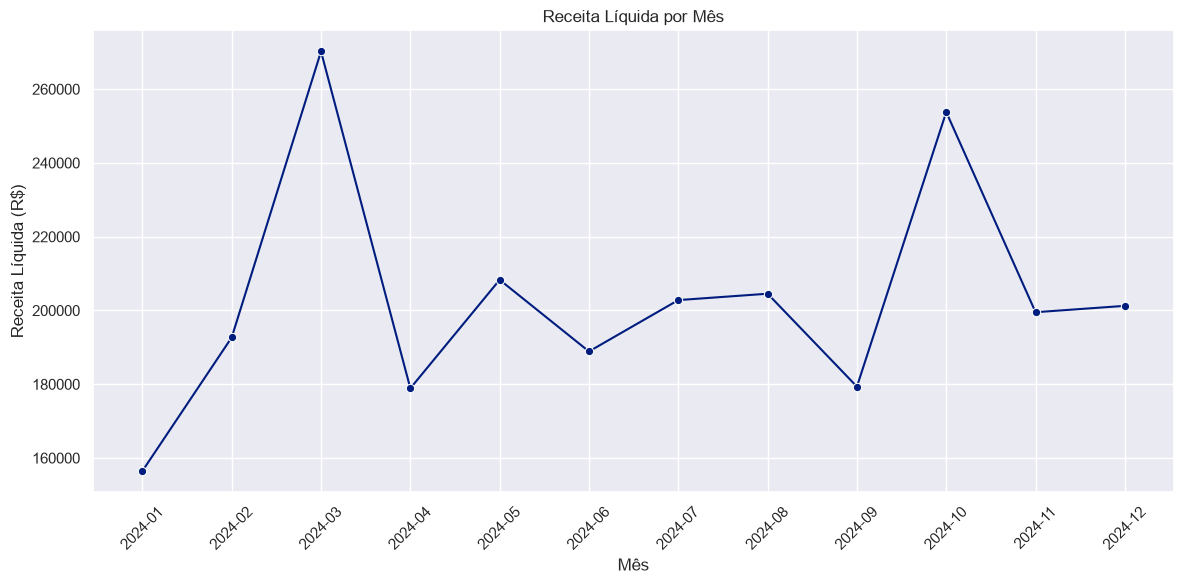

In [ ]:
sns.set_theme(
    style="darkgrid",  # Grid option: darkgrid, whitegrid, dark, white, ticks
    palette="muted",  # Color palette: deep, muted, bright, pastel, dark, colorblind
    context="notebook",  # Scale: paper, notebook, talk, poster
    font="sans-serif",  # Font family
)

# Recalcular a receita líquida para este exemplo funcionar isoladamente
df["receita_liquida"] = (
        df["quantidade"] * df["preco_unitario"] * (1 - df["desconto_pct"] / 100)
)
df["mes"] = pd.to_datetime(df["data"]).dt.to_period("M")
por_mes = (
    df.groupby("mes", as_index=False)["receita_liquida"]
        .sum()
        .sort_values("mes")
)
por_mes["mes"] = por_mes["mes"].astype(str)
fig, ax = plt.subplots()
sns.lineplot(data=por_mes, x="mes", y="receita_liquida",
    marker="o", ax=ax)
ax.set_title("Receita Líquida por Mês")
ax.set_xlabel("Mês")
ax.set_ylabel("Receita Líquida (R$)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show() 
